# Calibration-aware physical layout

**Question:** Does choosing physical qubits using their calibration errors improve this circuit's resources or noisy results?

I compare Qiskit's automatic layout with a layout selected from a small set of explicit mappings. I compile each candidate, estimate its error exposure from the backend's native gate and readout error data, and keep the lowest-scoring mapping. The final comparison uses separate compilation seeds and the same noisy-sampling budget for both methods.

The problem, trained-angle snapshot, objective, backend and shots come from the shared setup. The current backend is FakeManilaV2. A second backend is deliberately left for a later study.

## 1. Load the shared problem

The setup notebook defines the fixed circuit, `score`, backend and shot counts used by the other experiments.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware_experiments/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('docs/hardware_experiments/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Inspect the calibration snapshot

Each physical qubit and native gate has an estimated error in the backend target. The search below uses these values to score compiled circuits. They are a snapshot from a simulator backend, not a guarantee of future hardware performance.

In [2]:
physical_qubits = list(range(backend.num_qubits))
target = backend.target

calibration_rows = []
for physical in physical_qubits:
    measure = target['measure'].get((physical,))
    sx = target['sx'].get((physical,)) if 'sx' in target.operation_names else None
    calibration_rows.append({
        'physical qubit': physical,
        'readout error': None if measure is None else measure.error,
        'SX error': None if sx is None else sx.error,
    })
calibration = pd.DataFrame(calibration_rows)
display(calibration.style.format({'readout error': '{:.3%}', 'SX error': '{:.3%}'}))

edge_rows = []
for name in target.operation_names:
    for qubits, properties in target[name].items():
        if qubits is not None and len(qubits) == 2 and properties.error is not None:
            edge_rows.append({
                'native gate': name,
                'physical pair': f'{qubits[0]}-{qubits[1]}',
                'gate error': properties.error,
            })
native_edges = pd.DataFrame(edge_rows)
display(native_edges.style.format({'gate error': '{:.3%}'}))

,physical qubit,readout error,SX error
0,0,3.530%,0.016%
1,1,2.190%,0.039%
2,2,9.640%,0.075%
3,3,1.440%,0.021%
4,4,1.860%,0.035%


,native gate,physical pair,gate error
0,cx,0-1,0.883%
1,cx,1-0,0.883%
2,cx,1-2,1.394%
3,cx,2-1,1.394%
4,cx,2-3,1.135%
5,cx,3-2,1.135%
6,cx,3-4,0.570%
7,cx,4-3,0.570%


## 3. Search a small set of layouts

A layout tuple maps logical qubits to physical qubits in order: for example, `(2, 0, 1)` places logical qubits 0, 1 and 2 on physical qubits 2, 0 and 1. I include the identity mapping and try up to 119 more mappings with a fixed random seed.

For each candidate, I transpile with SABRE routing on two **discovery seeds**. The score adds `-log(1 - error)` for each native operation, including readout. Lower means less estimated error exposure. This is only a ranking heuristic: it assumes listed errors combine independently and does not directly predict mean cost or optimum frequency.

In [3]:
import math
max_candidates = 120
candidate_limit = min(max_candidates, math.perm(len(physical_qubits), n))
rng = np.random.default_rng(17)
candidates = [tuple(range(n))]
while len(candidates) < candidate_limit:
    proposal = tuple(int(q) for q in rng.choice(physical_qubits, size=n, replace=False))
    if proposal not in candidates:
        candidates.append(proposal)

print(f'Trying {len(candidates)} candidate layouts on {backend.num_qubits} physical qubits.')
print('Discovery seeds:', [1001, 1002])

Trying 120 candidate layouts on 5 physical qubits.
Discovery seeds: [1001, 1002]


In [4]:
def error_exposure(circuit):
    """Sum -log(1-error) for native gates and measurements in a compiled circuit."""
    total = 0.0
    unscored = 0
    for item in circuit.data:
        name = item.operation.name
        if name == 'barrier':
            continue
        qubits = tuple(circuit.find_bit(q).index for q in item.qubits)
        properties = target[name].get(qubits) if name in target.operation_names else None
        if properties is None or properties.error is None:
            unscored += 1
            continue
        error = min(max(float(properties.error), 0.0), 1.0 - 1e-12)
        total -= np.log1p(-error)
    return total, unscored


discovery_rows = []
for candidate_id, layout in enumerate(candidates):
    for seed in [1001, 1002]:
        manager = generate_preset_pass_manager(
            backend=backend,
            optimization_level=2,
            initial_layout=list(layout),
            routing_method='sabre',
            seed_transpiler=seed,
        )
        compiled_candidate = manager.run(make_circuit())
        exposure, unscored = error_exposure(compiled_candidate)
        discovery_rows.append({
            'candidate': candidate_id,
            'layout': layout,
            'seed': seed,
            'estimated error exposure': exposure,
            'unscored operations': unscored,
            **resources(compiled_candidate),
        })

discovery = pd.DataFrame(discovery_rows)
layout_scores = (discovery.groupby(['candidate', 'layout'], as_index=False)
                 .median(numeric_only=True)
                 .sort_values(['estimated error exposure', '2q gates', 'depth']))
selected_layout = tuple(layout_scores.iloc[0]['layout'])
print('Selected layout:', selected_layout)
display(layout_scores.head(8).style.format({
    'estimated error exposure': '{:.4f}',
    '2q gates': '{:.0f}',
    '2q depth': '{:.0f}',
    'depth': '{:.0f}',
}))

Selected layout: (3, 4, 2, 1, 0)


,candidate,layout,seed,estimated error exposure,unscored operations,2q gates,2q depth,depth
94,94,"(3, 4, 2, 1, 0)",1001.500000,0.4635,0.000000,25,20,48
30,30,"(4, 3, 2, 1, 0)",1001.500000,0.4699,0.000000,26,21,50
51,51,"(2, 3, 4, 1, 0)",1001.500000,0.4789,0.000000,27,22,46
76,76,"(3, 2, 4, 1, 0)",1001.500000,0.4823,0.000000,27,22,46
111,111,"(1, 0, 2, 3, 4)",1001.500000,0.4851,0.000000,25,20,53
95,95,"(4, 2, 3, 1, 0)",1001.500000,0.4880,0.000000,28,23,46
0,0,"(0, 1, 2, 3, 4)",1001.500000,0.4943,0.000000,26,21,57
75,75,"(2, 1, 0, 3, 4)",1001.500000,0.5068,0.000000,27,22,50


The two seeds above are used only to choose the candidate. The next section compiles and evaluates the selected layout on the shared evaluation seeds, which are separate from discovery.

## 4. Compare layouts on held-out seeds

The baseline lets Qiskit choose the layout automatically. The second method fixes the calibration-selected layout. Optimization level and SABRE routing are identical. Each evaluation seed is paired across the two methods.

In [5]:
methods = {'Automatic': None, 'Calibration selected': list(selected_layout)}
compiled = {}
resource_rows = []

for method, layout in methods.items():
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend,
            optimization_level=2,
            initial_layout=layout,
            routing_method='sabre',
            seed_transpiler=seed,
        )
        circuit = manager.run(make_circuit())
        compiled[method, seed] = circuit
        exposure, unscored = error_exposure(circuit)
        resource_rows.append({
            'method': method,
            'seed': seed,
            'estimated error exposure': exposure,
            'unscored operations': unscored,
            **resources(circuit),
        })

resource_table = pd.DataFrame(resource_rows)
resource_summary = resource_table.groupby('method')[
    ['estimated error exposure', '2q gates', '2q depth', 'depth']
].median().round(3)
display(resource_summary)

,estimated error exposure,2q gates,2q depth,depth
method,,,,
Automatic,0.482,27.0,22.0,46.0
Calibration selected,0.488,27.0,22.0,51.0


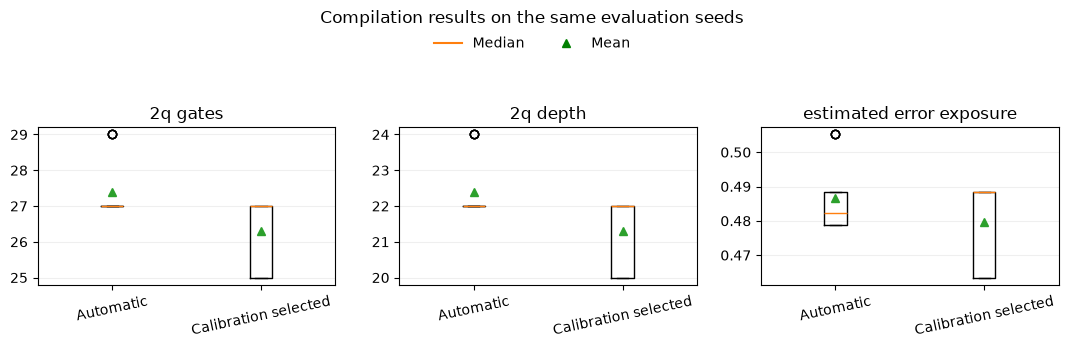

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, metric in zip(axes, ['2q gates', '2q depth', 'estimated error exposure']):
    data = [resource_table.loc[resource_table.method == name, metric]
            for name in methods]
    ax.boxplot(data, tick_labels=methods.keys(), showmeans=True)
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=12)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Compilation results on the same evaluation seeds')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, .84))
plt.show()

The error-exposure score shows how the calibration heuristic ranked the compiled results. Gate counts and depth show the routing cost. A lower proxy does not guarantee better samples, so the next section checks noisy outcomes directly.

## 5. Compare noisy samples

For each method I simulate the same three compiled seeds, with three repeats of 2,048 shots per seed. Both methods use the same simulator seed for each matched seed and repeat, so the sampling is reproducible. This is a small pilot; the repeated samples are not independent backend calibrations.

In [7]:
run_noise = True
if run_noise:
    if backend.num_qubits > 16:
        raise ValueError('Choose a smaller simulator or turn off noisy sampling above 16 qubits.')
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    sample_rows = []
    for method in methods:
        for seed in noise_seeds:
            for repeat in range(noise_repeats):
                sample_seed = 10000 + seed * noise_repeats + repeat
                counts = simulator.run(
                    compiled[method, seed], shots=shots, seed_simulator=sample_seed
                ).result().get_counts()
                metrics = score(counts)
                sample_rows.append({
                    'method': method,
                    'seed': seed,
                    'repeat': repeat,
                    **metrics,
                })
    noisy_results = pd.DataFrame(sample_rows)
    noise_summary = noisy_results.groupby('method')[
        ['mean cost', 'optimum frequency']
    ].median().round(4)
    display(noise_summary)

,mean cost,optimum frequency
method,,
Automatic,9.4253,0.2822
Calibration selected,9.3408,0.2861


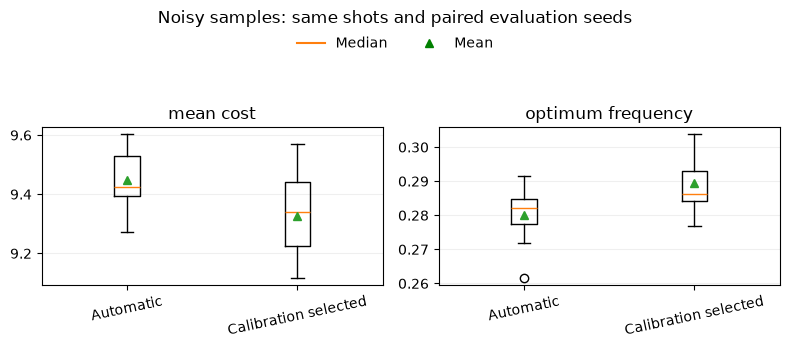

In [8]:
if run_noise:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        data = [noisy_results.loc[noisy_results.method == name, metric]
                for name in methods]
        ax.boxplot(data, tick_labels=methods.keys(), showmeans=True)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=12)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy samples: same shots and paired evaluation seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, .84))
    plt.show()

## What did I find?

The search selected `(3, 4, 2, 1, 0)`, mapping logical qubits 0–4 onto those physical qubits. Across the 20 held-out compilation seeds, this layout matched automatic layout's median two-qubit count (27) and two-qubit depth (22). Its median total depth was higher (51 versus 46), and its estimated error exposure was slightly higher (0.488 versus 0.482).

In the noisy samples, median mean cost was 9.341 for the selected layout and 9.425 for automatic layout; median optimum frequency was 0.286 versus 0.282. Those small differences across three compiled seeds and three repeats do not show a clear advantage. Qiskit's automatic layout is already competitive here. The error-exposure score is only a simple proxy; it omits correlated errors, idle noise and how each error affects this objective.

## Later: add another backend

The second backend is intentionally deferred. For that comparison, choose a backend with calibration data and enough connected, usable qubits, change the backend in `hardware_setup.ipynb`, rerun this notebook, and compare both methods on that backend's own calibration snapshot. Keep the problem, angles, scoring, shots and discovery/evaluation split fixed. Do not combine results from two backends into one claim.

## References

- Qiskit explains how its layout stage maps logical qubits to physical qubits, and how explicit `initial_layout` controls that mapping: [Qiskit transpiler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/transpiler).
- The error values used here come from the backend's instruction target; IBM documents backend calibration data and readout error: [View backend details](https://qiskit.qotlabs.org/docs/guides/qpu-information).
- This experiment follows the general idea of choosing circuit mappings using operation-specific calibration error estimates. It uses a much smaller, simpler search than the published method: [UREQA, USENIX ATC 2020](https://www.usenix.org/conference/atc20/presentation/patel).
- Earlier calibration-aware placement work studies the effect of mapping and scheduling on execution reliability: [Noise-Adaptive Compiler Mappings, ASPLOS 2019](https://arxiv.org/abs/1901.11054).